In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
import os.path
import cv2 as cv
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns
from time import perf_counter
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,accuracy_score
from IPython.display import Markdown, display

In [ ]:
def proc_img(filepath):
    """ Create a DataFrame with the filepath and the labels of the pictures"""

    labels = list(map(lambda x: os.path.split(os.path.split(x)[0])[1], filepath))

    filepath = pd.Series(filepath, name='Filepath').astype(str)
    labels = pd.Series(labels, name='Label')

    df = pd.concat([filepath, labels], axis=1)
    df = df.sample(frac=1).reset_index(drop = True)

    return df

# Create a list with the filepaths
train_dir = Path('/content/drive/MyDrive/Data_set_for_DL/train')
filepaths = list(train_dir.glob(r'**/*.jpg'))

test_dir=Path('/content/drive/MyDrive/Data_set_for_DL/test')
filepaths_test = list(test_dir.glob(r'**/*.jpg'))

val_dir=Path('/content/drive/MyDrive/Data_set_for_DL/valid')
filepaths_valid = list(val_dir.glob(r'**/*.jpg'))

df_train = proc_img(filepaths)
df_test = proc_img(filepaths_test)
df_valid=proc_img(filepaths_valid)


In [ ]:
df_train.head()

,Filepath,Label
0,/content/drive/MyDrive/Data_set_for_DL/train/n...,nowildfire
1,/content/drive/MyDrive/Data_set_for_DL/train/w...,wildfire
2,/content/drive/MyDrive/Data_set_for_DL/train/n...,nowildfire
3,/content/drive/MyDrive/Data_set_for_DL/train/w...,wildfire
4,/content/drive/MyDrive/Data_set_for_DL/train/n...,nowildfire


In [ ]:
def print_df(df):

    print(f'Number of pictures: {df.shape[0]}\n')
    print(f'Number of different labels: {len(df.Label.unique())}\n')
    print(f'Labels: {df.Label.unique()}')
def printhead(df):
    print(df.head(5))


In [ ]:
print("length of image is: ", plt.imread(df_test["Filepath"][0]).shape[0], "width is: ", plt.imread(df_test["Filepath"][0]).shape[1]," and number of channels are: ", plt.imread(df_test["Filepath"][0]).shape[2])

length of image is:  350 width is:  350  and number of channels are:  3


In [ ]:
printhead(df_train)

                                            Filepath       Label
0  /content/drive/MyDrive/Data_set_for_DL/train/n...  nowildfire
1  /content/drive/MyDrive/Data_set_for_DL/train/w...    wildfire
2  /content/drive/MyDrive/Data_set_for_DL/train/n...  nowildfire
3  /content/drive/MyDrive/Data_set_for_DL/train/w...    wildfire
4  /content/drive/MyDrive/Data_set_for_DL/train/n...  nowildfire


In [ ]:
print_df(df_train)

Number of pictures: 30331

Number of different labels: 2

Labels: ['nowildfire' 'wildfire']


In [ ]:
print_df(df_test)

Number of pictures: 6316

Number of different labels: 2

Labels: ['wildfire' 'nowildfire']


In [ ]:
print_df(df_valid)

Number of pictures: 6300

Number of different labels: 2

Labels: ['wildfire' 'nowildfire']


In [ ]:
def viz_img(df):
    df_1 = df.copy().reset_index()
    fig, axes = plt.subplots( nrows=2,ncols=3, figsize=(20, 10), subplot_kw={'xticks': [], 'yticks': []})
    for i, ax in enumerate(axes.flat):
        ax.imshow(plt.imread(df_1.Filepath[i]))
        ax.set_title(df_1.Label[i])
    plt.tight_layout(pad=0.5)
    plt.show()

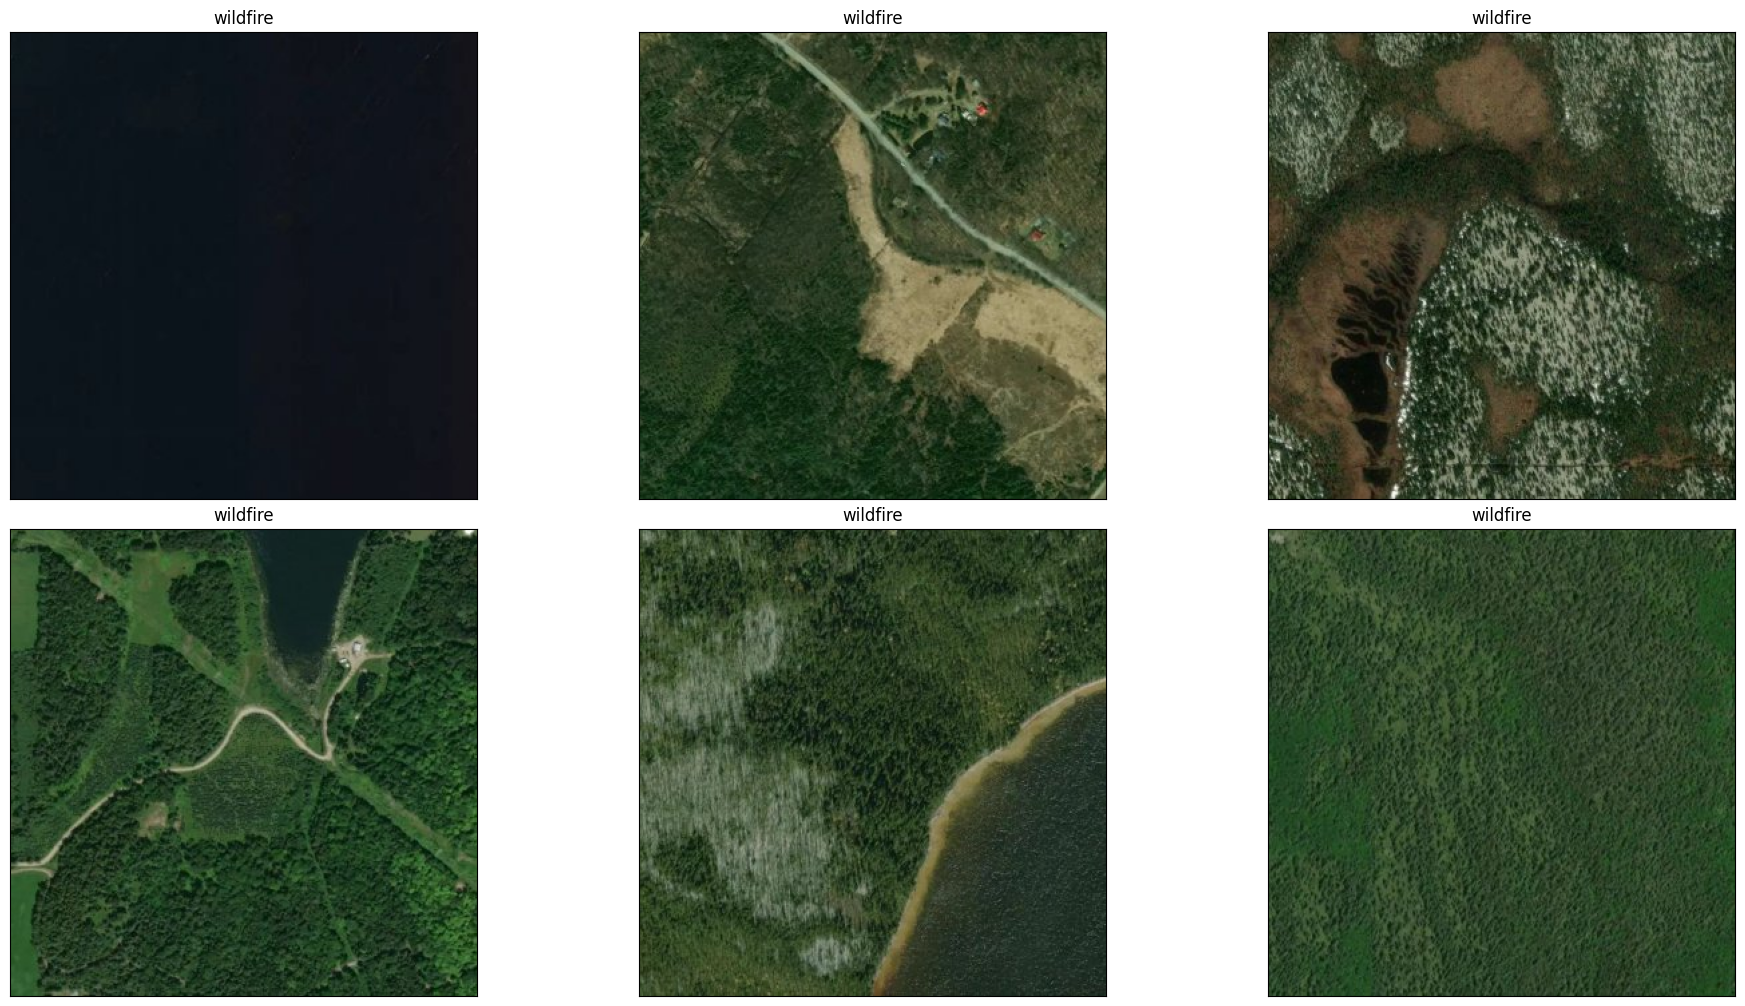

In [ ]:
df1=df_train.copy()
df1=df1[df1.Label=='wildfire']
viz_img(df1)

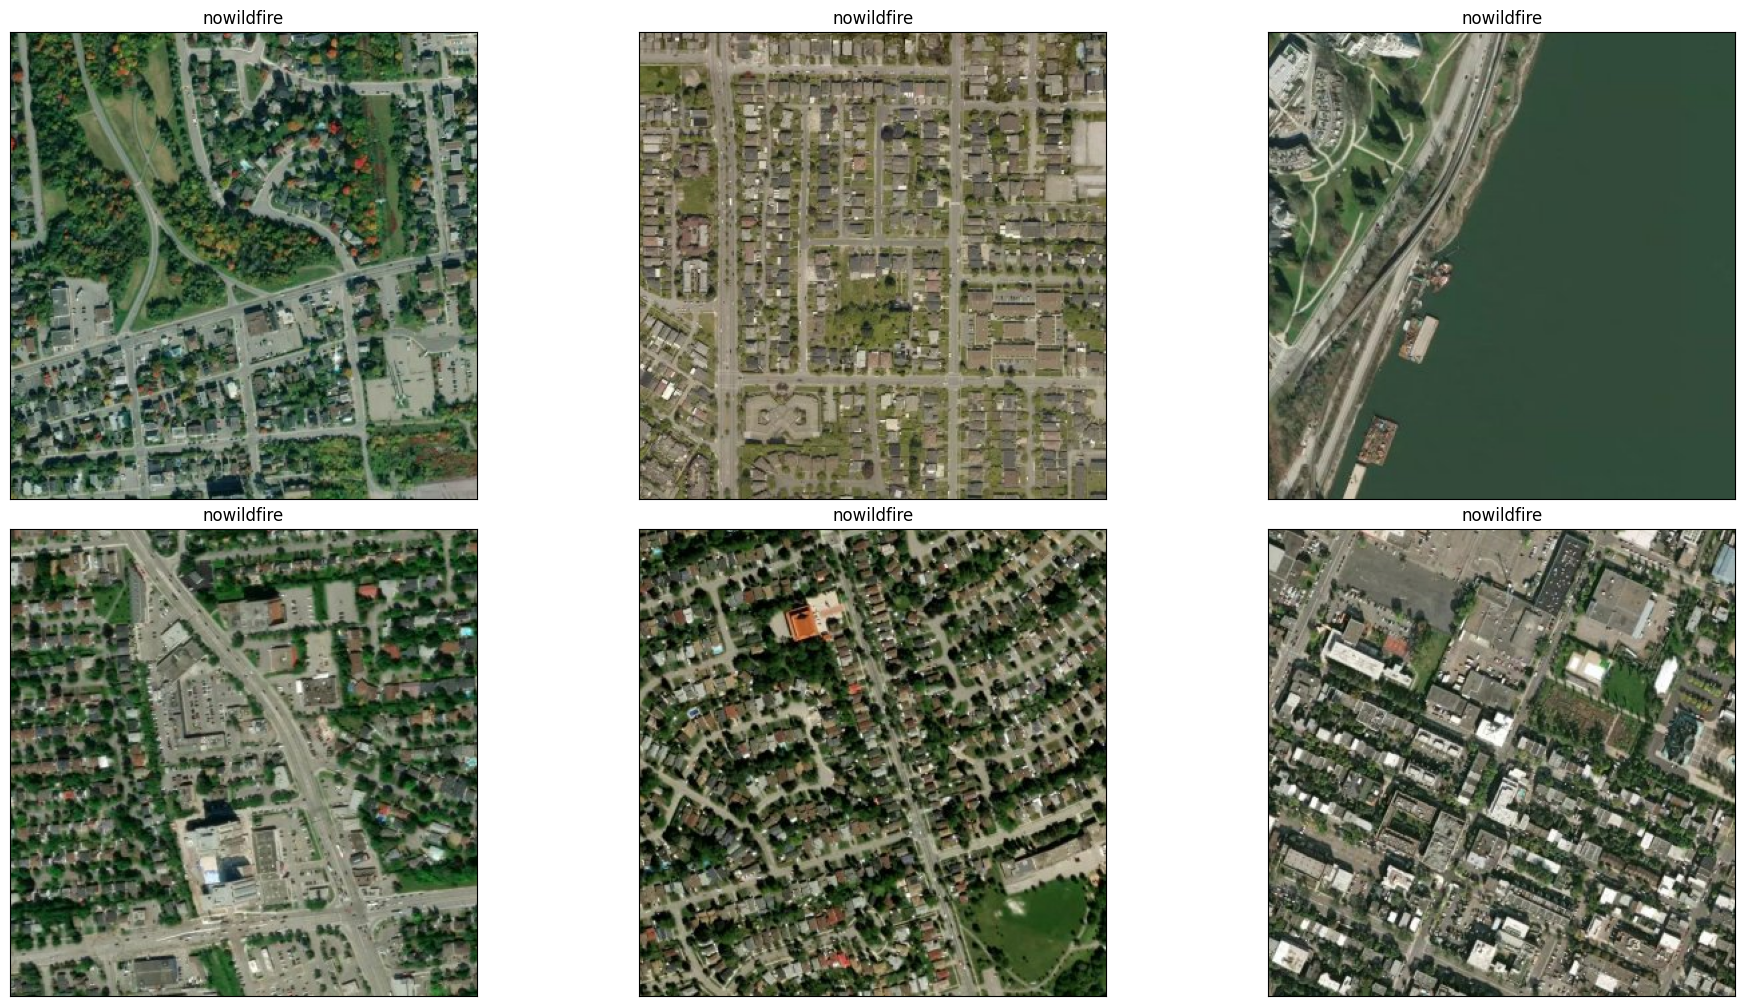

In [ ]:
df1=df_train.copy()
df1=df1[df1.Label=='nowildfire']
viz_img(df1)


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import albumentations as A

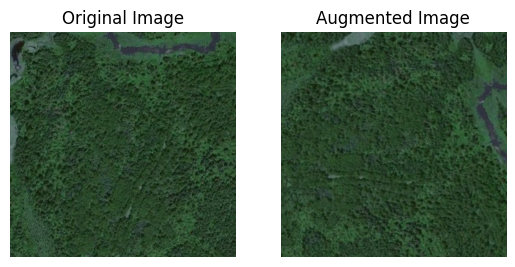

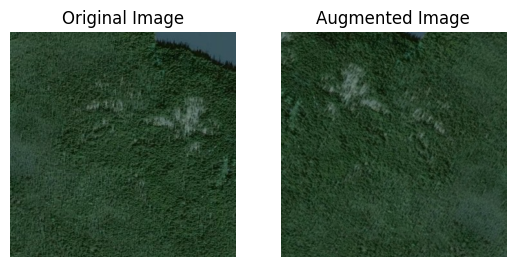

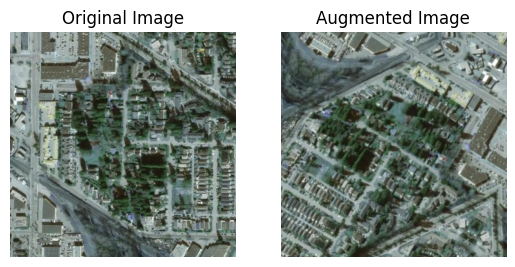

In [ ]:
def augment_image(image):
    aug = A.Compose([
        A.Flip(),
        A.Rotate(limit=75,always_apply=True),
    ])
    augmented_image = aug(image=image)['image']
    return augmented_image
def show_original_augment_image(df):
    random_data = df.sample(n=3)
    for i in range(len(random_data)):
        image = cv.imread(random_data.iloc[i].Filepath)
        augmented_image = augment_image(image)

        plt.subplot(1,2,1)
        plt.imshow(image)
        plt.axis('off')
        plt.title("Original Image")

        plt.subplot(1,2,2)
        plt.imshow(augmented_image)
        plt.title("Augmented Image")
        plt.axis('off')
        plt.show()

show_original_augment_image(df_train)

In [ ]:
print("length of image is:", plt.imread(df_valid["Filepath"][0]).shape[0], "width is:", plt.imread(df_valid["Filepath"][0]).shape[1],"and number of channels are:", plt.imread(df_test["Filepath"][0]).shape[2])

length of image is: 350 width is: 350 and number of channels are: 3


In [ ]:
BATCH_SIZE = 256
train_datagen = ImageDataGenerator(dtype='float32', rescale= 1./255., preprocessing_function=augment_image)
train_generator = train_datagen.flow_from_dataframe(df_train,
                                                    x_col='Filepath',
                                                    y_col='Label',
                                                    shuffle=True,
                                                    batch_size = BATCH_SIZE,
                                                    target_size = (350,350),
                                                    class_mode = 'categorical')
val_datagen = ImageDataGenerator(dtype='float32', rescale= 1./255.)
val_generator = val_datagen.flow_from_dataframe(df_valid,
                                                    x_col='Filepath',
                                                    y_col='Label',
                                                    shuffle=True,
                                                    batch_size = BATCH_SIZE,
                                                    target_size = (350,350),
                                                    class_mode = 'categorical')
test_datagen = ImageDataGenerator(dtype='float32', rescale= 1./255.)
test_generator = test_datagen.flow_from_dataframe(df_test,
                                                    x_col='Filepath',
                                                    y_col='Label',
                                                    shuffle=False,
                                                    batch_size = BATCH_SIZE,
                                                    target_size = (350,350),
                                                    class_mode = 'categorical')


Found 30331 validated image filenames belonging to 2 classes.
Found 6300 validated image filenames belonging to 2 classes.
Found 6316 validated image filenames belonging to 2 classes.


In [ ]:
df_train.shape

(30331, 2)

In [ ]:
import tensorflow as tf
from tensorflow.keras import optimizers, regularizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, BatchNormalization, Conv2D, MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

In [ ]:
image_shape = (349, 349, 3)

In [ ]:
weight_decay = 1e-3
first_model = Sequential([
    Conv2D(filters = 8 , kernel_size = 2, activation = 'relu',
    input_shape = image_shape), MaxPooling2D(pool_size = 2),

    Conv2D(filters = 16 , kernel_size = 2, activation = 'relu',
    input_shape = image_shape), MaxPooling2D(pool_size = 2),

    Conv2D(filters = 32 , kernel_size = 2, activation = 'relu',
           kernel_regularizer = regularizers.l2(weight_decay)),
    MaxPooling2D(pool_size = 2),


    Flatten(),
    Dense(300,activation='relu'),
    Dropout(0.5),
    Dense(100,activation='relu'),
    Dropout(0.4),
    Dense(2,activation='softmax')
])
first_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 348, 348, 8)       104       
                                                                 
 max_pooling2d (MaxPooling2  (None, 174, 174, 8)       0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 173, 173, 16)      528       
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 86, 86, 16)        0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 85, 85, 32)        2080      
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 42, 42, 32)        0

In [ ]:
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

checkpointer = ModelCheckpoint('first_model.hdf5',verbose=1, save_best_only= True)
early_stopping = EarlyStopping(monitor= 'val_loss', patience= 10)

optimizer = optimizers.Adam(learning_rate= 0.00001, weight_decay= 1e-5)
checkpointer = ModelCheckpoint('first_model.hdf5',verbose=1, save_best_only= True)
early_stopping = EarlyStopping(monitor= 'val_loss', patience= 10)
optimizer = optimizers.Adam(learning_rate= 0.00001, weight_decay= 1e-5)
first_model.compile(loss= 'categorical_crossentropy', optimizer= 'adam',
                    metrics=['AUC','acc'])
history = first_model.fit(train_generator,
                    epochs = 10,
                    verbose = 1,
                    validation_data = val_generator,
                    callbacks = [checkpointer, early_stopping])

Epoch 1/10
 14/119 [==>...........................] - ETA: 2:27:19 - loss: 1.1272 - auc: 0.5664 - acc: 0.5460

## Model Evaluation on Test Set
Load the best saved checkpoint and evaluate on the held-out test data.

In [ ]:
from tensorflow.keras.models import load_model

# Load the best checkpoint saved during training
best_model = load_model("first_model.hdf5")
print("Model loaded successfully.")

In [ ]:
import numpy as np

# Reset generator so predictions align with true labels
test_generator.reset()

y_pred_prob = best_model.predict(test_generator, verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)

y_true = test_generator.classes
class_labels = list(test_generator.class_indices.keys())
print("Classes:", class_labels)

In [ ]:
from sklearn.metrics import accuracy_score

acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {acc * 100:.2f}%")

In [ ]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_labels))

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_labels, yticklabels=class_labels)
plt.title("Confusion Matrix - Test Set", fontsize=14)
plt.ylabel("Actual Label", fontsize=12)
plt.xlabel("Predicted Label", fontsize=12)
plt.tight_layout()
plt.show()

## Training History
Visualise how loss and AUC evolved across epochs.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
axes[0].plot(history.history["loss"], label="Train Loss", marker="o")
axes[0].plot(history.history["val_loss"], label="Val Loss", marker="o")
axes[0].set_title("Loss Over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# AUC curve
auc_key = "auc" if "auc" in history.history else list(history.history.keys())[1]
val_auc_key = "val_auc" if "val_auc" in history.history else "val_" + auc_key
axes[1].plot(history.history[auc_key], label="Train AUC", marker="o")
axes[1].plot(history.history[val_auc_key], label="Val AUC", marker="o")
axes[1].set_title("AUC Over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUC")
axes[1].legend()
axes[1].grid(True)

plt.suptitle("Training History", fontsize=16)
plt.tight_layout()
plt.show()

## Sample Predictions
Visualise individual test images alongside their predicted and actual labels. Green title = correct, Red = wrong.

In [ ]:
import cv2 as cv

sample_df = df_test.sample(n=9, random_state=42).reset_index(drop=True)

fig, axes = plt.subplots(3, 3, figsize=(15, 15),
                         subplot_kw={"xticks": [], "yticks": []})

for i, ax in enumerate(axes.flat):
    img = plt.imread(sample_df.Filepath[i])
    img_resized = cv.resize(img, (349, 349)) / 255.0
    pred_prob = best_model.predict(img_resized[np.newaxis, ...], verbose=0)
    pred_label = class_labels[np.argmax(pred_prob)]
    actual_label = sample_df.Label[i]
    color = "green" if pred_label == actual_label else "red"
    ax.imshow(img)
    ax.set_title(f"Actual: {actual_label}\nPredicted: {pred_label}",
                 color=color, fontsize=11)

plt.suptitle("Sample Test Predictions  (Green=Correct | Red=Wrong)",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()